In [ ]:
print("="*60)
print("IMPLEMENTASI DATASET 2 (BANKSIM) SESUAI JURNAL")
print("="*60)

import pandas as pd
import numpy as np
import os

# Load Dataset 2
dataset2_path = '/Users/apple/Desktop/Skripsi/ExIFFI/dataset/bs140513_032310.csv'
print(f"Loading Dataset 2 from: {dataset2_path}")

df_banksim = pd.read_csv(dataset2_path)

print(f"\n=== DATASET 2 INFORMATION ===")
print(f"Shape: {df_banksim.shape}")
print(f"Columns: {df_banksim.columns.tolist()}")
print(f"\nData types:")
print(df_banksim.dtypes)
print(f"\nFirst 5 rows:")
print(df_banksim.head())

# Rename columns untuk konsistensi
df_banksim = df_banksim.rename(columns={
    'zipcodeOri': 'customer_zip',
    'zipMerchant': 'merchant_zip',
    'fraud': 'Class'  # Untuk konsistensi dengan dataset 1
})

print(f"\n=== TARGET DISTRIBUTION ===")
print(df_banksim['Class'].value_counts())
print(f"Fraud percentage: {(df_banksim['Class'].sum() / len(df_banksim)) * 100:.4f}%")

print(f"\n=== UNIQUE VALUES PER COLUMN ===")
for col in df_banksim.columns:
    if df_banksim[col].dtype == 'object':
        unique_count = df_banksim[col].nunique()
        print(f"{col:15s}: {unique_count:6d} unique values")
    else:
        print(f"{col:15s}: Numerical")

print(f"\n=== STATISTICAL SUMMARY ===")
print(df_banksim.describe())

IMPLEMENTASI DATASET 2 (BANKSIM) SESUAI JURNAL
Loading Dataset 2 from: /Users/apple/Desktop/Skripsi/ExIFFI/dataset/bs140513_032310.csv

=== DATASET 2 INFORMATION ===
Shape: (594643, 10)
Columns: ['step', 'customer', 'age', 'gender', 'zipcodeOri', 'merchant', 'zipMerchant', 'category', 'amount', 'fraud']

Data types:
step             int64
customer        object
age             object
gender          object
zipcodeOri      object
merchant        object
zipMerchant     object
category        object
amount         float64
fraud            int64
dtype: object

First 5 rows:
   step       customer  age gender zipcodeOri       merchant zipMerchant  \
0     0  'C1093826151'  '4'    'M'    '28007'   'M348934600'     '28007'   
1     0   'C352968107'  '2'    'M'    '28007'   'M348934600'     '28007'   
2     0  'C2054744914'  '4'    'F'    '28007'  'M1823072687'     '28007'   
3     0  'C1760612790'  '3'    'M'    '28007'   'M348934600'     '28007'   
4     0   'C757503768'  '5'    'M'    '2800

In [6]:
print("\n" + "="*60)
print("PROPER DATA CLEANING FOR BANKSIM DATASET")
print("="*60)

# Load dataset
dataset2_path = '/Users/apple/Desktop/Skripsi/ExIFFI/dataset/bs140513_032310.csv'
df_banksim = pd.read_csv(dataset2_path)

print(f"Dataset loaded: {df_banksim.shape}")
print(f"Columns: {df_banksim.columns.tolist()}")

# Show sample data
print(f"\n=== SAMPLE DATA (WITH QUOTES) ===")
print(df_banksim.head(3))

# Clean all columns by removing quotes
print(f"\n=== CLEANING ALL COLUMNS (REMOVING QUOTES) ===")

def clean_quotes(value):
    """Remove quotes from string values"""
    if isinstance(value, str):
        # Remove single and double quotes
        value = value.replace('"', '').replace("'", '').strip()
        # Try to convert to numeric if possible
        try:
            return float(value) if '.' in value else int(value)
        except:
            return value
    return value

# Apply cleaning to all columns
df_clean = df_banksim.copy()
for col in df_clean.columns:
    df_clean[col] = df_clean[col].apply(clean_quotes)

print(f"\n=== SAMPLE DATA AFTER CLEANING ===")
print(df_clean.head(3))

# Verify data types
print(f"\n=== DATA TYPES AFTER CLEANING ===")
print(df_clean.dtypes)

# Convert specific columns to proper types
print(f"\n=== CONVERTING TO PROPER DATA TYPES ===")

# Convert 'age' to integer
print(f"Converting 'age' to integer...")
df_clean['age'] = pd.to_numeric(df_clean['age'], errors='coerce').fillna(0).astype(int)

# Convert 'amount' to float
print(f"Converting 'amount' to float...")
df_clean['amount'] = pd.to_numeric(df_clean['amount'], errors='coerce')

# Convert 'fraud' to integer (binary)
print(f"Converting 'fraud' to integer...")
df_clean['fraud'] = pd.to_numeric(df_clean['fraud'], errors='coerce').fillna(0).astype(int)

# Verify conversions
print(f"\n=== FINAL DATA TYPES ===")
print(df_clean.dtypes)

print(f"\n=== SAMPLE DATA FINAL ===")
print(df_clean.head(5))

print(f"\n=== STATISTICAL SUMMARY ===")
print(df_clean.describe())

# Check unique values
print(f"\n=== UNIQUE VALUES PER COLUMN ===")
for col in df_clean.columns:
    unique_count = df_clean[col].nunique()
    sample_values = df_clean[col].unique()[:5] if unique_count > 5 else df_clean[col].unique()
    print(f"{col:15s}: {unique_count:6d} unique | Sample: {sample_values}")

print(f"\n=== TARGET DISTRIBUTION ===")
print(df_clean['fraud'].value_counts())
print(f"Fraud percentage: {(df_clean['fraud'].sum() / len(df_clean)) * 100:.4f}%")

# Save cleaned data
output_dir = '/Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/'
import os
os.makedirs(output_dir, exist_ok=True)

cleaned_path = os.path.join(output_dir, 'banksim_cleaned.csv')
df_clean.to_csv(cleaned_path, index=False)
print(f"\nCleaned data saved to: {cleaned_path}")


PROPER DATA CLEANING FOR BANKSIM DATASET
Dataset loaded: (594643, 10)
Columns: ['step', 'customer', 'age', 'gender', 'zipcodeOri', 'merchant', 'zipMerchant', 'category', 'amount', 'fraud']

=== SAMPLE DATA (WITH QUOTES) ===
   step       customer  age gender zipcodeOri       merchant zipMerchant  \
0     0  'C1093826151'  '4'    'M'    '28007'   'M348934600'     '28007'   
1     0   'C352968107'  '2'    'M'    '28007'   'M348934600'     '28007'   
2     0  'C2054744914'  '4'    'F'    '28007'  'M1823072687'     '28007'   

              category  amount  fraud  
0  'es_transportation'    4.55      0  
1  'es_transportation'   39.68      0  
2  'es_transportation'   26.89      0  

=== CLEANING ALL COLUMNS (REMOVING QUOTES) ===

=== SAMPLE DATA AFTER CLEANING ===
   step     customer age gender  zipcodeOri     merchant  zipMerchant  \
0     0  C1093826151   4      M       28007   M348934600        28007   
1     0   C352968107   2      M       28007   M348934600        28007   
2     0

In [7]:
print("\n" + "="*60)
print("FEATURE ENGINEERING FOR CLEANED BANKSIM DATASET")
print("="*60)

def create_banksim_features_fixed(df):
    """
    Create rule-based features for CLEANED BankSim dataset
    """
    df_features = df.copy()
    
    print("Creating comprehensive feature engineering...")
    
    # ==================== 1. RENAME COLUMNS FOR CONSISTENCY ====================
    df_features = df_features.rename(columns={
        'zipcodeOri': 'customer_zip',
        'zipMerchant': 'merchant_zip',
        'fraud': 'Class'  # Untuk konsistensi
    })
    
    # ==================== 2. TEMPORAL FEATURES ====================
    print("\n1. Temporal Features:")
    
    # a. Transaction hour (assuming 'step' is in hours)
    df_features['transaction_hour'] = df_features['step'] % 24
    df_features['hour_sin'] = np.sin(2 * np.pi * df_features['transaction_hour'] / 24)
    df_features['hour_cos'] = np.cos(2 * np.pi * df_features['transaction_hour'] / 24)
    
    # b. Day of week (assuming 24 steps = 1 day)
    df_features['day_of_week'] = (df_features['step'] // 24) % 7
    df_features['is_weekend'] = df_features['day_of_week'].isin([5, 6]).astype(int)
    
    # c. Time of day categories
    df_features['time_of_day'] = pd.cut(df_features['transaction_hour'], 
                                        bins=[0, 6, 12, 18, 24],
                                        labels=['Night', 'Morning', 'Afternoon', 'Evening'],
                                        include_lowest=True)
    
    # Convert to dummy variables
    time_dummies = pd.get_dummies(df_features['time_of_day'], prefix='time')
    df_features = pd.concat([df_features, time_dummies], axis=1)
    
    print(f"   Created: hour_sin/cos, day_of_week, is_weekend, time_of_day dummies")
    
    # ==================== 3. CUSTOMER BEHAVIOR FEATURES ====================
    print("\n2. Customer Behavior Features:")
    
    # Hitung statistics per customer
    customer_stats = df_features.groupby('customer').agg({
        'amount': ['mean', 'std', 'min', 'max', 'count'],
        'step': ['min', 'max']
    }).reset_index()
    
    customer_stats.columns = ['customer', 'cust_avg_amount', 'cust_std_amount',
                             'cust_min_amount', 'cust_max_amount', 'cust_transaction_count',
                             'cust_first_transaction', 'cust_last_transaction']
    
    # Merge dengan data utama
    df_features = pd.merge(df_features, customer_stats, on='customer', how='left')
    
    # a. Deviation from customer's normal behavior
    df_features['amount_deviation'] = (df_features['amount'] - df_features['cust_avg_amount']) / df_features['cust_std_amount'].replace(0, 1)
    df_features['amount_deviation'] = df_features['amount_deviation'].fillna(0)
    
    # b. Transaction frequency
    df_features['cust_transaction_freq'] = df_features['cust_transaction_count'] / (df_features['cust_last_transaction'] - df_features['cust_first_transaction'] + 1)
    
    # c. Time since last transaction (per customer)
    df_features['time_since_last'] = df_features.groupby('customer')['step'].diff().fillna(24)
    
    print(f"   Created: customer stats, amount deviation, transaction frequency, time since last")
    
    # ==================== 4. DEMOGRAPHIC FEATURES ====================
    print("\n3. Demographic Features:")
    
    # a. Age groups (FIXED - sekarang 'age' sudah integer)
    df_features['age_group'] = pd.cut(df_features['age'], 
                                      bins=[0, 25, 35, 45, 55, 65, 100],
                                      labels=['<25', '25-35', '35-45', '45-55', '55-65', '65+'])
    
    age_dummies = pd.get_dummies(df_features['age_group'], prefix='age')
    df_features = pd.concat([df_features, age_dummies], axis=1)
    
    # b. Gender encoding (FIXED - sudah cleaned)
    df_features['gender_M'] = (df_features['gender'] == 'M').astype(int)
    df_features['gender_F'] = (df_features['gender'] == 'F').astype(int)
    df_features['gender_U'] = (df_features['gender'] == 'U').astype(int)
    
    # c. Age-risk interaction
    amount_q75 = df_features['amount'].quantile(0.75)
    df_features['young_high_amount'] = ((df_features['age'] < 30) & (df_features['amount'] > amount_q75)).astype(int)
    
    print(f"   Created: age groups, gender encoding, age-risk interactions")
    
    # ==================== 5. MERCHANT & CATEGORY FEATURES ====================
    print("\n4. Merchant & Category Features:")
    
    # a. Merchant risk score
    merchant_fraud_rate = df_features.groupby('merchant')['Class'].mean()
    df_features['merchant_fraud_rate'] = df_features['merchant'].map(merchant_fraud_rate).fillna(0)
    
    # b. Category encoding
    category_dummies = pd.get_dummies(df_features['category'], prefix='category')
    df_features = pd.concat([df_features, category_dummies], axis=1)
    
    # c. Unusual category for customer
    customer_categories = df_features.groupby('customer')['category'].apply(lambda x: x.mode()[0] if len(x.mode()) > 0 else 'unknown').to_dict()
    df_features['usual_category'] = df_features.apply(
        lambda row: 1 if row['category'] == customer_categories.get(row['customer'], 'unknown') else 0,
        axis=1
    )
    
    print(f"   Created: merchant fraud rate, category dummies, usual category")
    
    # ==================== 6. AMOUNT-BASED FEATURES ====================
    print("\n5. Amount-Based Features:")
    
    # a. Amount categories
    df_features['amount_category'] = pd.qcut(df_features['amount'], q=5, labels=['Very_Low', 'Low', 'Medium', 'High', 'Very_High'])
    amount_dummies = pd.get_dummies(df_features['amount_category'], prefix='amount_cat')
    df_features = pd.concat([df_features, amount_dummies], axis=1)
    
    # b. Amount outliers
    amount_mean = df_features['amount'].mean()
    amount_std = df_features['amount'].std()
    df_features['amount_zscore'] = (df_features['amount'] - amount_mean) / amount_std
    df_features['high_amount'] = (df_features['amount_zscore'] > 3).astype(int)
    df_features['very_low_amount'] = (df_features['amount_zscore'] < -3).astype(int)
    
    # c. Amount relative to customer history
    df_features['amount_vs_cust_avg'] = df_features['amount'] / df_features['cust_avg_amount'].replace(0, 1)
    
    print(f"   Created: amount categories, z-score, high/low flags, relative amount")
    
    # ==================== 7. GEOGRAPHICAL FEATURES ====================
    print("\n6. Geographical Features:")
    
    # a. Zipcode features (FIXED - sudah cleaned)
    df_features['customer_zip_prefix'] = df_features['customer_zip'].astype(str).str[:3]
    df_features['merchant_zip_prefix'] = df_features['merchant_zip'].astype(str).str[:3]
    df_features['same_zip_area'] = (df_features['customer_zip_prefix'] == df_features['merchant_zip_prefix']).astype(int)
    
    # b. Unusual location
    customer_zip_history = df_features.groupby('customer')['customer_zip_prefix'].apply(set).to_dict()
    df_features['new_zip_area'] = df_features.apply(
        lambda row: 0 if row['merchant_zip_prefix'] in customer_zip_history.get(row['customer'], set()) else 1,
        axis=1
    )
    
    print(f"   Created: same zip area, new zip area")
    
    # ==================== 8. RULE-BASED COMBINATION FEATURES ====================
    print("\n7. Rule-Based Combination Features:")
    
    # Combination rules
    df_features['high_amount_new_location'] = (df_features['high_amount'] & df_features['new_zip_area']).astype(int)
    df_features['night_transaction_high_amount'] = ((df_features['time_of_day'] == 'Night') & df_features['high_amount']).astype(int)
    df_features['weekend_unusual_category'] = (df_features['is_weekend'] & (df_features['usual_category'] == 0)).astype(int)
    df_features['young_new_merchant'] = ((df_features['age'] < 25) & df_features['new_zip_area']).astype(int)
    
    print(f"   Created: combination rules")
    
    # ==================== 9. FINAL CLEANUP ====================
    print("\n8. Final Cleanup:")
    
    # Drop helper columns
    cols_to_drop = ['time_of_day', 'age_group', 'amount_category', 
                   'customer_zip_prefix', 'merchant_zip_prefix',
                   'transaction_hour', 'day_of_week', 'gender']
    
    df_features = df_features.drop(columns=cols_to_drop, errors='ignore')
    
    # Identify rule-based features
    rule_based_patterns = ['high_amount', 'very_low_amount', 'same_zip_area', 'new_zip_area',
                          'is_weekend', 'young_high_amount', 'usual_category',
                          'high_amount_new_location', 'night_transaction_high_amount',
                          'weekend_unusual_category', 'young_new_merchant',
                          'gender_', 'time_', 'age_', 'category_', 'amount_cat_']
    
    rule_based_features = [col for col in df_features.columns if any(pattern in col for pattern in rule_based_patterns)]
    
    print(f"   Total features: {df_features.shape[1]}")
    print(f"   Rule-based features: {len(rule_based_features)}")
    
    return df_features, rule_based_features

# Apply feature engineering
df_banksim_enhanced, rule_based_features = create_banksim_features_fixed(df_clean)

print(f"\n" + "="*60)
print("FEATURE ENGINEERING COMPLETED SUCCESSFULLY!")
print("="*60)

print(f"\n=== FINAL DATASET SHAPE ===")
print(f"Original shape: {df_banksim.shape}")
print(f"Enhanced shape: {df_banksim_enhanced.shape}")
print(f"Features added: {df_banksim_enhanced.shape[1] - df_banksim.shape[1]}")

print(f"\n=== SAMPLE OF ENHANCED DATA ===")
print("First 5 rows, first 10 columns:")
print(df_banksim_enhanced.iloc[:5, :10])

print(f"\n=== RULE-BASED FEATURES CREATED ===")
print(f"Total: {len(rule_based_features)}")
for i, feat in enumerate(rule_based_features[:20]):  # Show first 20
    print(f"  {i+1:2d}. {feat}")
if len(rule_based_features) > 20:
    print(f"  ... and {len(rule_based_features) - 20} more")

# Save enhanced dataset
enhanced_path = os.path.join(output_dir, 'banksim_enhanced.pkl')
import joblib

banksim_enhanced_data = {
    'df': df_banksim_enhanced,
    'rule_based_features': rule_based_features,
    'dataset_info': {
        'original_samples': len(df_banksim),
        'enhanced_samples': len(df_banksim_enhanced),
        'total_features': df_banksim_enhanced.shape[1],
        'original_features': df_banksim.shape[1],
        'engineered_features': df_banksim_enhanced.shape[1] - df_banksim.shape[1],
        'fraud_rate': df_banksim_enhanced['Class'].mean() * 100
    }
}

joblib.dump(banksim_enhanced_data, enhanced_path)
print(f"\nEnhanced dataset saved to: {enhanced_path}")


FEATURE ENGINEERING FOR CLEANED BANKSIM DATASET
Creating comprehensive feature engineering...

1. Temporal Features:
   Created: hour_sin/cos, day_of_week, is_weekend, time_of_day dummies

2. Customer Behavior Features:
   Created: customer stats, amount deviation, transaction frequency, time since last

3. Demographic Features:
   Created: age groups, gender encoding, age-risk interactions

4. Merchant & Category Features:
   Created: merchant fraud rate, category dummies, usual category

5. Amount-Based Features:
   Created: amount categories, z-score, high/low flags, relative amount

6. Geographical Features:
   Created: same zip area, new zip area

7. Rule-Based Combination Features:
   Created: combination rules

8. Final Cleanup:
   Total features: 68
   Rule-based features: 45

FEATURE ENGINEERING COMPLETED SUCCESSFULLY!

=== FINAL DATASET SHAPE ===
Original shape: (594643, 10)
Enhanced shape: (594643, 68)
Features added: 58

=== SAMPLE OF ENHANCED DATA ===
First 5 rows, first 

In [11]:
print("="*60)
print("AUTOENCODER IMPLEMENTATION FOR BANKSIM DATASET")
print("(According to AE-EIF Paper Methodology)")
print("="*60)

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

# Load enhanced BankSim data
output_dir = '/Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/'
banksim_data = joblib.load(os.path.join(output_dir, 'banksim_enhanced.pkl'))
df_enhanced = banksim_data['df']

print("=== DATASET LOADED ===")
print(f"Dataset shape: {df_enhanced.shape}")
print(f"Features: {df_enhanced.shape[1] - 1}")  # minus Class
print(f"Fraud rate: {df_enhanced['Class'].mean()*100:.4f}%")
print(f"Fraud samples: {df_enhanced['Class'].sum():,}")

# Separate features and target
X = df_enhanced.drop('Class', axis=1)
y = df_enhanced['Class']

print(f"\nFeature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")

# ==================== DATA PREPROCESSING ====================
print("\n" + "="*60)
print("DATA PREPROCESSING FOR AUTOENCODER")
print("="*60)

print("\n1. Handling categorical features...")
# Identify categorical columns (non-numeric)
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
print(f"   Categorical columns: {categorical_cols}")

if categorical_cols:
    # Label encoding for categorical features
    from sklearn.preprocessing import LabelEncoder
    label_encoders = {}
    for col in categorical_cols:
        le = LabelEncoder()
        X[col] = le.fit_transform(X[col].astype(str))
        label_encoders[col] = le
        print(f"   Encoded '{col}' - {len(le.classes_)} classes")
else:
    print("   No categorical columns found")

print(f"\n2. Feature scaling...")
# Use RobustScaler to handle outliers
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

print(f"   Original data range:")
print(f"     Min: {X.values.min():.4f}, Max: {X.values.max():.4f}")
print(f"     Mean: {X.values.mean():.4f}, Std: {X.values.std():.4f}")

print(f"\n   Scaled data range:")
print(f"     Min: {X_scaled.min():.4f}, Max: {X_scaled.max():.4f}")
print(f"     Mean: {X_scaled.mean():.4f}, Std: {X_scaled.std():.4f}")

# ==================== DATA SPLITTING (SESUAI JURNAL) ====================
print("\n" + "="*60)
print("DATA SPLITTING ACCORDING TO JOURNAL")
print("="*60)

print("\nAccording to journal (Section 7.2.2):")
print("- AutoEncoder trained ONLY on NORMAL transactions")
print("- Training: 70% of normal transactions")
print("- Threshold determination: Remaining 30% of training set")
print("- EIF training: Uses threshold-determined data")

# Separate normal and fraud data
X_normal = X_scaled[y == 0]
X_fraud = X_scaled[y == 1]
y_normal = y[y == 0]
y_fraud = y[y == 1]

print(f"\nNormal transactions: {len(X_normal):,}")
print(f"Fraud transactions: {len(X_fraud):,}")
print(f"Fraud percentage: {len(X_fraud)/len(X_scaled)*100:.4f}%")

# Split normal data: 70% for AE training, 30% for threshold determination
X_train_normal, X_temp_normal = train_test_split(
    X_normal, test_size=0.3, random_state=42
)

print(f"\nAE Training data (normal only): {len(X_train_normal):,}")
print(f"Threshold determination data: {len(X_temp_normal):,}")

# Test set: 30% normal + all fraud
X_test_normal = X_temp_normal
X_test = np.vstack([X_test_normal, X_fraud])
y_test = np.concatenate([np.zeros(len(X_test_normal)), np.ones(len(X_fraud))])

print(f"\nTest data:")
print(f"  Normal in test: {len(X_test_normal):,}")
print(f"  Fraud in test: {len(X_fraud):,}")
print(f"  Total test: {len(X_test):,}")
print(f"  Test fraud rate: {y_test.mean()*100:.4f}%")

# ==================== AUTOENCODER ARCHITECTURE (SESUAI JURNAL) ====================
print("\n" + "="*60)
print("AUTOENCODER ARCHITECTURE (According to Section 6.1)")
print("="*60)

print("\nJournal specifications:")
print("- Input layer: n features")
print("- Hidden layers: 14 → 7 → 14 nodes")  
print("- Output layer: n features (reconstruction)")
print("- Activation: ReLU")
print("- Training: Only on normal transactions")

input_dim = X_train_normal.shape[1]
encoding_dim1 = 14  # First hidden layer
encoding_dim2 = 7   # Bottleneck layer (compressed representation)
encoding_dim3 = 14  # Third hidden layer

print(f"\nAutoEncoder Configuration for BankSim:")
print(f"Input dimension: {input_dim} features")
print(f"Architecture: Input({input_dim}) → Dense({encoding_dim1}) → Dense({encoding_dim2})")
print(f"               → Dense({encoding_dim3}) → Output({input_dim})")
print(f"Training samples: {len(X_train_normal):,} (normal only)")

# Set random seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

# Build AutoEncoder
print("\nBuilding AutoEncoder model...")

input_layer = Input(shape=(input_dim,), name='input')

# Encoder
encoded1 = Dense(encoding_dim1, activation='relu', name='encoder1')(input_layer)
encoded1_bn = BatchNormalization(name='bn1')(encoded1)
encoded1_drop = Dropout(0.1, name='dropout1')(encoded1_bn)

encoded2 = Dense(encoding_dim2, activation='relu', name='encoder2')(encoded1_drop)
encoded2_bn = BatchNormalization(name='bn2')(encoded2)  # Bottleneck

encoded3 = Dense(encoding_dim3, activation='relu', name='encoder3')(encoded2_bn)
encoded3_bn = BatchNormalization(name='bn3')(encoded3)
encoded3_drop = Dropout(0.1, name='dropout2')(encoded3_bn)

# Decoder
decoded1 = Dense(encoding_dim2, activation='relu', name='decoder1')(encoded3_drop)
decoded1_bn = BatchNormalization(name='bn4')(decoded1)

decoded2 = Dense(encoding_dim1, activation='relu', name='decoder2')(decoded1_bn)
decoded2_bn = BatchNormalization(name='bn5')(decoded2)

output_layer = Dense(input_dim, activation='linear', name='output')(decoded2_bn)

# Create models
autoencoder = Model(inputs=input_layer, outputs=output_layer, name='AutoEncoder')
encoder = Model(inputs=input_layer, outputs=encoded2_bn, name='Encoder')  # For μ feature extraction

print("\nAutoEncoder Summary:")
autoencoder.summary()

print(f"\nEncoder (for μ features) Summary:")
encoder.summary()

# ==================== TRAINING AUTOENCODER ====================
print("\n" + "="*60)
print("TRAINING AUTOENCODER (Section 6.3.1)")
print("="*60)

# Compile model
autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',  # Mean Squared Error for reconstruction
    metrics=['mae', tf.keras.metrics.CosineSimilarity()]
)

# Callbacks
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=7,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=os.path.join(output_dir, 'banksim_autoencoder_best.h5'),
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

print(f"\nTraining configuration:")
print(f"- Epochs: 100")
print(f"- Batch size: 32")
print(f"- Validation split: 0.2")
print(f"- Early stopping patience: 15")
print(f"- Learning rate reduction patience: 7")

# Train AutoEncoder
print("\nStarting AutoEncoder training...")
history = autoencoder.fit(
    X_train_normal, X_train_normal,  # Autoencoder learns to reconstruct its input
    epochs=10,
    batch_size=32,
    shuffle=True,
    validation_split=0.2,
    callbacks=callbacks,
    verbose=1
)

print("\nAutoEncoder training completed!")

# Save final model
autoencoder.save(os.path.join(output_dir, 'banksim_autoencoder_final.h5'))
encoder.save(os.path.join(output_dir, 'banksim_encoder_final.h5'))
print(f"\nModels saved to {output_dir}")

AUTOENCODER IMPLEMENTATION FOR BANKSIM DATASET
(According to AE-EIF Paper Methodology)
=== DATASET LOADED ===
Dataset shape: (594643, 68)
Features: 67
Fraud rate: 1.2108%
Fraud samples: 7,200

Feature matrix shape: (594643, 67)
Target vector shape: (594643,)

DATA PREPROCESSING FOR AUTOENCODER

1. Handling categorical features...
   Categorical columns: ['customer', 'merchant', 'category']
   Encoded 'customer' - 4112 classes
   Encoded 'merchant' - 50 classes
   Encoded 'category' - 15 classes

2. Feature scaling...
   Original data range:
     Min: -1.7180, Max: 28007.0000
     Mean: 882.8325, Std: 4768.1242

   Scaled data range:
     Min: -105.0000, Max: 288.3007
     Mean: 0.1222, Std: 1.6729

DATA SPLITTING ACCORDING TO JOURNAL

According to journal (Section 7.2.2):
- AutoEncoder trained ONLY on NORMAL transactions
- Training: 70% of normal transactions
- Threshold determination: Remaining 30% of training set
- EIF training: Uses threshold-determined data

Normal transactions: 58

Model: "AutoEncoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 67)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder1 (Dense)                │ (None, 14)             │           952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 14)             │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 14)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder2 (Dense)                │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 7)              │            28 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder3 (Dense)                │ (None, 14)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 14)             │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 14)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder1 (Dense)                │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 7)              │            28 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder2 (Dense)                │ (None, 14)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn5 (BatchNormalization)        │ (None, 14)             │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 67)             │         1,005 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,615 (10.21 KB)

 Trainable params: 2,503 (9.78 KB)

...

10281/10281 ━━━━━━━━━━━━━━━━━━━━ 75s 7ms/step - cosine_similarity: 0.6047 - loss: 0.4232 - mae: 0.2644 - val_cosine_similarity: 0.7054 - val_loss: 0.2622 - val_mae: 0.2114 - learning_rate: 0.0010
Epoch 9/10
10276/10281 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - cosine_similarity: 0.6033 - loss: 0.4201 - mae: 0.2638
Epoch 9: val_loss improved from 0.26218 to 0.25519, saving model to /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/banksim_autoencoder_best.h5


10281/10281 ━━━━━━━━━━━━━━━━━━━━ 69s 7ms/step - cosine_similarity: 0.6027 - loss: 0.4204 - mae: 0.2642 - val_cosine_similarity: 0.7003 - val_loss: 0.2552 - val_mae: 0.2135 - learning_rate: 0.0010
Epoch 10/10
10277/10281 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - cosine_similarity: 0.6010 - loss: 0.4174 - mae: 0.2638
Epoch 10: val_loss improved from 0.25519 to 0.25275, saving model to /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/banksim_autoencoder_best.h5


10281/10281 ━━━━━━━━━━━━━━━━━━━━ 71s 7ms/step - cosine_similarity: 0.6000 - loss: 0.4173 - mae: 0.2641 - val_cosine_similarity: 0.6924 - val_loss: 0.2528 - val_mae: 0.2149 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 10.



AutoEncoder training completed!



Models saved to /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/



TRAINING RESULTS VISUALIZATION


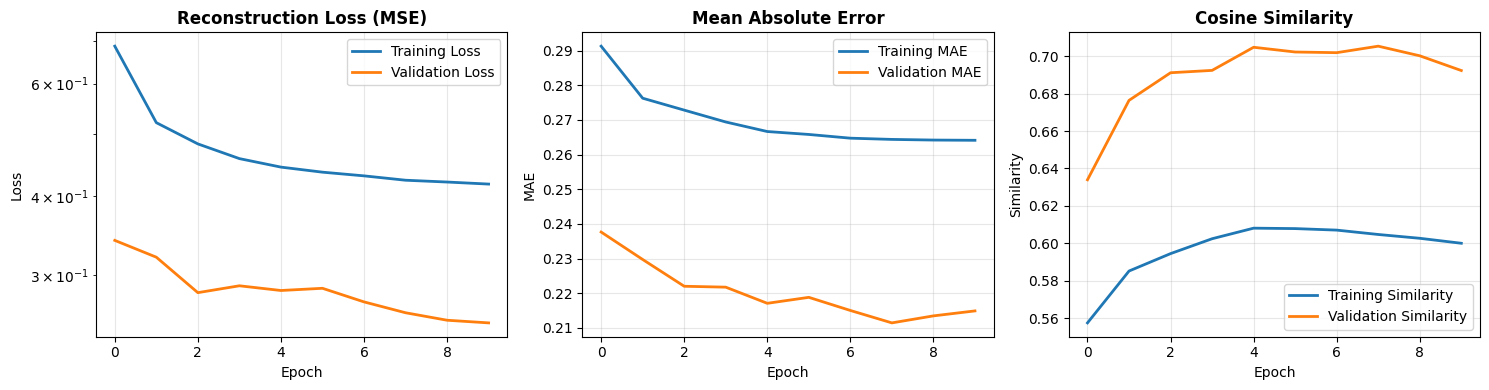


=== FINAL TRAINING METRICS ===
Final training loss: 0.417335
Final validation loss: 0.252751
Final training MAE: 0.264100
Final validation MAE: 0.214884
Best validation loss: 0.252751
Best epoch: 10


In [12]:
print("\n" + "="*60)
print("TRAINING RESULTS VISUALIZATION")
print("="*60)

# Plot training history
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Loss (MSE)
axes[0].plot(history.history['loss'], label='Training Loss', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0].set_title('Reconstruction Loss (MSE)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_yscale('log')

# 2. MAE
axes[1].plot(history.history['mae'], label='Training MAE', linewidth=2)
axes[1].plot(history.history['val_mae'], label='Validation MAE', linewidth=2)
axes[1].set_title('Mean Absolute Error', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# 3. Cosine Similarity
axes[2].plot(history.history['cosine_similarity'], label='Training Similarity', linewidth=2)
axes[2].plot(history.history['val_cosine_similarity'], label='Validation Similarity', linewidth=2)
axes[2].set_title('Cosine Similarity', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Similarity')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print final metrics
print("\n=== FINAL TRAINING METRICS ===")
print(f"Final training loss: {history.history['loss'][-1]:.6f}")
print(f"Final validation loss: {history.history['val_loss'][-1]:.6f}")
print(f"Final training MAE: {history.history['mae'][-1]:.6f}")
print(f"Final validation MAE: {history.history['val_mae'][-1]:.6f}")
print(f"Best validation loss: {min(history.history['val_loss']):.6f}")
print(f"Best epoch: {history.history['val_loss'].index(min(history.history['val_loss'])) + 1}")

In [13]:
print("\n" + "="*60)
print("EXTRACTING μ FEATURES (Section 6.3.2)")
print("="*60)

print("\nAccording to journal:")
print("μ = [A, B, C] where:")
print("A: Compressed representation from AutoEncoder")
print("B: Euclidean distance between input and reconstruction")
print("C: Similarity degree between input and reconstruction")

# Get reconstructions for test data
print(f"\n1. Generating reconstructions for test data...")
reconstructions = autoencoder.predict(X_test, verbose=1)

# Calculate reconstruction errors
print(f"\n2. Calculating reconstruction errors...")
mse_per_sample = np.mean(np.square(X_test - reconstructions), axis=1)
mae_per_sample = np.mean(np.abs(X_test - reconstructions), axis=1)

print(f"   Reconstruction error statistics:")
print(f"   MSE - Min: {mse_per_sample.min():.6f}, Max: {mse_per_sample.max():.6f}")
print(f"        Mean: {mse_per_sample.mean():.6f}, Std: {mse_per_sample.std():.6f}")

# Calculate μ features
print(f"\n3. Calculating μ features...")

# A: Compressed representation (from bottleneck layer)
print("   A: Getting compressed representation...")
A_features = encoder.predict(X_test, verbose=1)  # Output from bottleneck (7 dimensions)

# B: Euclidean distance (reconstruction error)
print("   B: Calculating Euclidean distance...")
B_features = np.sqrt(np.sum(np.square(X_test - reconstructions), axis=1, keepdims=True))

# C: Similarity degree (cosine similarity)
print("   C: Calculating cosine similarity...")
from sklearn.metrics.pairwise import cosine_similarity

C_features = np.array([cosine_similarity([X_test[i]], [reconstructions[i]])[0][0] 
                       for i in range(len(X_test))])
C_features = C_features.reshape(-1, 1)

print(f"\nμ features extracted:")
print(f"A (compressed): shape {A_features.shape}")
print(f"B (Euclidean):  shape {B_features.shape}")
print(f"C (similarity): shape {C_features.shape}")
print(f"Total μ features per sample: {A_features.shape[1] + B_features.shape[1] + C_features.shape[1]}")

# Combine all μ features
mu_features = np.hstack([A_features, B_features, C_features])
print(f"\nCombined μ features shape: {mu_features.shape}")

# Save μ features
mu_features_path = os.path.join(output_dir, 'banksim_mu_features.pkl')
joblib.dump({
    'A_features': A_features,
    'B_features': B_features,
    'C_features': C_features,
    'mu_features': mu_features,
    'reconstruction_errors': mse_per_sample,
    'reconstructions': reconstructions
}, mu_features_path)
print(f"\nμ features saved to: {mu_features_path}")


EXTRACTING μ FEATURES (Section 6.3.2)

According to journal:
μ = [A, B, C] where:
A: Compressed representation from AutoEncoder
B: Euclidean distance between input and reconstruction
C: Similarity degree between input and reconstruction

1. Generating reconstructions for test data...
5733/5733 ━━━━━━━━━━━━━━━━━━━━ 5s 888us/step

2. Calculating reconstruction errors...
   Reconstruction error statistics:
   MSE - Min: 0.039264, Max: 2642.496673
        Mean: 1.771343, Std: 33.017194

3. Calculating μ features...
   A: Getting compressed representation...
5733/5733 ━━━━━━━━━━━━━━━━━━━━ 5s 775us/step
   B: Calculating Euclidean distance...
   C: Calculating cosine similarity...

μ features extracted:
A (compressed): shape (183433, 7)
B (Euclidean):  shape (183433, 1)
C (similarity): shape (183433, 1)
Total μ features per sample: 9

Combined μ features shape: (183433, 9)

μ features saved to: /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/banksim_mu_features.pkl



THRESHOLD DETERMINATION (Section 6.3.1)

According to journal:
- Calculate reconstruction errors on training data (normal only)
- Determine threshold based on percentile
- Flag transactions above threshold as suspicious

1. Calculating reconstruction errors on training data (normal only)...

2. Threshold determination:
   Using 95th percentile of training reconstruction errors
   Threshold value: 0.599825
   Training MSE statistics:
     Mean: 0.250548
     Std:  1.547579
     Min:  0.039654
     Max:  199.825028
     95th percentile: 0.599825

3. Suspicious transaction identification:
   Total test transactions: 183,433
   Suspicious transactions (AE): 15,215 (8.29%)
   Normal transactions (AE): 168,218 (91.71%)

   Actual fraud detected as suspicious: 6,532
   Actual fraud missed: 668
   False positives (normal flagged as suspicious): 8,683


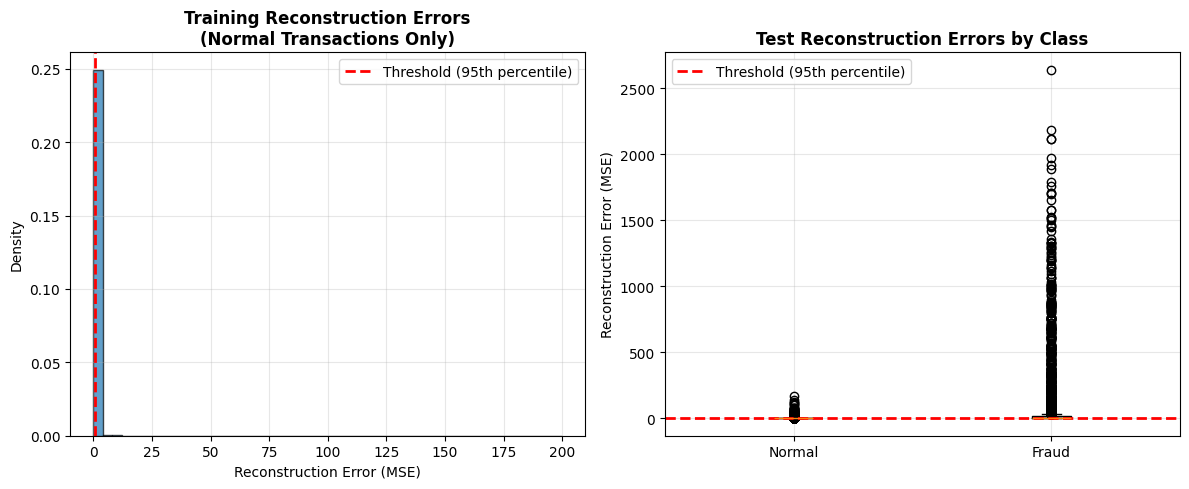

In [14]:
print("\n" + "="*60)
print("THRESHOLD DETERMINATION (Section 6.3.1)")
print("="*60)

print("\nAccording to journal:")
print("- Calculate reconstruction errors on training data (normal only)")
print("- Determine threshold based on percentile")
print("- Flag transactions above threshold as suspicious")

# Calculate reconstruction errors on training data
print("\n1. Calculating reconstruction errors on training data (normal only)...")
train_reconstructions = autoencoder.predict(X_train_normal, verbose=0)
train_mse = np.mean(np.square(X_train_normal - train_reconstructions), axis=1)

# Determine threshold (sesuai jurnal: 95th percentile)
threshold_percentile = 95
threshold = np.percentile(train_mse, threshold_percentile)

print(f"\n2. Threshold determination:")
print(f"   Using {threshold_percentile}th percentile of training reconstruction errors")
print(f"   Threshold value: {threshold:.6f}")
print(f"   Training MSE statistics:")
print(f"     Mean: {train_mse.mean():.6f}")
print(f"     Std:  {train_mse.std():.6f}")
print(f"     Min:  {train_mse.min():.6f}")
print(f"     Max:  {train_mse.max():.6f}")
print(f"     {threshold_percentile}th percentile: {threshold:.6f}")

# Identify suspicious transactions
suspicious_mask = mse_per_sample > threshold
normal_mask = mse_per_sample <= threshold

print(f"\n3. Suspicious transaction identification:")
print(f"   Total test transactions: {len(X_test):,}")
print(f"   Suspicious transactions (AE): {suspicious_mask.sum():,} ({suspicious_mask.sum()/len(X_test)*100:.2f}%)")
print(f"   Normal transactions (AE): {normal_mask.sum():,} ({normal_mask.sum()/len(X_test)*100:.2f}%)")

print(f"\n   Actual fraud detected as suspicious: {(suspicious_mask & (y_test == 1)).sum():,}")
print(f"   Actual fraud missed: {(normal_mask & (y_test == 1)).sum():,}")
print(f"   False positives (normal flagged as suspicious): {(suspicious_mask & (y_test == 0)).sum():,}")

# Visualize threshold
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram of training reconstruction errors
axes[0].hist(train_mse, bins=50, alpha=0.7, edgecolor='black', density=True)
axes[0].axvline(x=threshold, color='red', linestyle='--', linewidth=2, 
                label=f'Threshold ({threshold_percentile}th percentile)')
axes[0].set_title('Training Reconstruction Errors\n(Normal Transactions Only)', fontweight='bold')
axes[0].set_xlabel('Reconstruction Error (MSE)')
axes[0].set_ylabel('Density')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Test data errors by class
test_mse_normal = mse_per_sample[y_test == 0]
test_mse_fraud = mse_per_sample[y_test == 1]

box_data = [test_mse_normal, test_mse_fraud]
axes[1].boxplot(box_data, labels=['Normal', 'Fraud'])
axes[1].axhline(y=threshold, color='red', linestyle='--', linewidth=2, 
                label=f'Threshold ({threshold_percentile}th percentile)')
axes[1].set_title('Test Reconstruction Errors by Class', fontweight='bold')
axes[1].set_ylabel('Reconstruction Error (MSE)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
print("\n" + "="*60)
print("PREPARING DATA FOR EXTENDED ISOLATION FOREST")
print("="*60)

print("\nAccording to journal Section 6.3.2:")
print("- EIF uses Ω (original) + μ (AE) features")
print("- EIF analyzes only suspicious transactions from AE")
print("- Ω features: original + rule-based features")
print("- μ features: A, B, C from AutoEncoder")

# Ω features: Original + Rule-based features (scaled)
omega_features = X_test  # Already scaled

print(f"\nΩ features (original + rule-based): shape {omega_features.shape}")

# Combine Ω + μ features
X_eif_input = np.hstack([omega_features, mu_features])

print(f"\nCombined features for EIF (Ω + μ):")
print(f"Ω features: {omega_features.shape[1]} features")
print(f"μ features: {mu_features.shape[1]} features")
print(f"Total features: {X_eif_input.shape[1]} features")

# Split data based on AE threshold
X_suspicious = X_eif_input[suspicious_mask]  # Untuk EIF analysis
X_normal_ae = X_eif_input[normal_mask]       # Sudah diklasifikasi normal oleh AE
y_suspicious = y_test[suspicious_mask]
y_normal_ae = y_test[normal_mask]

print(f"\nData split for AE-EIF pipeline:")
print(f"1. AE Normal (not sent to EIF): {X_normal_ae.shape[0]:,} samples")
print(f"2. AE Suspicious (sent to EIF): {X_suspicious.shape[0]:,} samples")
print(f"   - Actual fraud in suspicious: {y_suspicious.sum():,}")
print(f"   - Actual normal in suspicious: {(y_suspicious == 0).sum():,}")

# Save AE-EIF pipeline data
ae_eif_data = {
    # AutoEncoder models
    'autoencoder': autoencoder,
    'encoder': encoder,
    
    # Threshold information
    'threshold': threshold,
    'threshold_percentile': threshold_percentile,
    'suspicious_mask': suspicious_mask,
    'normal_mask': normal_mask,
    
    # μ features
    'A_features': A_features,
    'B_features': B_features,
    'C_features': C_features,
    'mu_features': mu_features,
    
    # Combined features
    'X_eif_input': X_eif_input,
    'X_suspicious': X_suspicious,
    'X_normal_ae': X_normal_ae,
    'y_suspicious': y_suspicious,
    'y_normal_ae': y_normal_ae,
    
    # Original data
    'X_test': X_test,
    'y_test': y_test,
    'reconstruction_errors': mse_per_sample,
    
    # Training history
    'history': history.history,
    
    # Metadata
    'metadata': {
        'dataset': 'BankSim',
        'input_dim': input_dim,
        'encoding_dims': [encoding_dim1, encoding_dim2, encoding_dim3],
        'total_test_samples': len(X_test),
        'suspicious_samples': suspicious_mask.sum(),
        'normal_samples_ae': normal_mask.sum(),
        'fraud_in_suspicious': y_suspicious.sum(),
        'fraud_in_normal_ae': (normal_mask & (y_test == 1)).sum(),
        'fraud_detection_rate_ae': (suspicious_mask & (y_test == 1)).sum() / y_test.sum() * 100,
        'false_positive_rate_ae': (suspicious_mask & (y_test == 0)).sum() / (y_test == 0).sum() * 100
    }
}

# Save to file
ae_eif_pipeline_path = os.path.join(output_dir, 'banksim_ae_eif_pipeline.pkl')
joblib.dump(ae_eif_data, ae_eif_pipeline_path)

print(f"\n=== AE-EIF PIPELINE DATA SAVED ===")
print(f"File: {ae_eif_pipeline_path}")

print(f"\n=== AUTOENCODER PERFORMANCE SUMMARY ===")
meta = ae_eif_data['metadata']
print(f"✅ 1. AutoEncoder trained successfully on {len(X_train_normal):,} normal transactions")
print(f"   - Architecture: {input_dim} → {encoding_dim1} → {encoding_dim2} → {encoding_dim3} → {input_dim}")
print(f"   - Final validation loss: {history.history['val_loss'][-1]:.6f}")
print(f"\n✅ 2. μ features extracted:")
print(f"   - A (compressed): {A_features.shape[1]} features")
print(f"   - B (Euclidean): {B_features.shape[1]} feature")
print(f"   - C (similarity): {C_features.shape[1]} feature")
print(f"   - Total μ: {mu_features.shape[1]} features")
print(f"\n✅ 3. Threshold determined:")
print(f"   - Threshold: {threshold:.6f} ({threshold_percentile}th percentile)")
print(f"   - Suspicious transactions: {meta['suspicious_samples']:,} ({meta['suspicious_samples']/meta['total_test_samples']*100:.1f}%)")
print(f"\n✅ 4. Fraud detection by AE:")
print(f"   - Fraud detected: {meta['fraud_in_suspicious']:,} out of {y_test.sum():,}")
print(f"   - Detection rate: {meta['fraud_detection_rate_ae']:.1f}%")
print(f"   - False positive rate: {meta['false_positive_rate_ae']:.1f}%")

print(f"\n" + "="*60)
print("NEXT STEP: EXTENDED ISOLATION FOREST (EIF)")
print("="*60)
print("\nReady to implement Extended Isolation Forest with:")
print(f"1. Ω features: {omega_features.shape[1]} (original + rule-based)")
print(f"2. μ features: {mu_features.shape[1]} (from AutoEncoder)")
print(f"3. Total features for EIF: {X_eif_input.shape[1]}")
print(f"4. Suspicious transactions to analyze: {X_suspicious.shape[0]:,}")


PREPARING DATA FOR EXTENDED ISOLATION FOREST

According to journal Section 6.3.2:
- EIF uses Ω (original) + μ (AE) features
- EIF analyzes only suspicious transactions from AE
- Ω features: original + rule-based features
- μ features: A, B, C from AutoEncoder

Ω features (original + rule-based): shape (183433, 67)

Combined features for EIF (Ω + μ):
Ω features: 67 features
μ features: 9 features
Total features: 76 features

Data split for AE-EIF pipeline:
1. AE Normal (not sent to EIF): 168,218 samples
2. AE Suspicious (sent to EIF): 15,215 samples
   - Actual fraud in suspicious: 6,532.0
   - Actual normal in suspicious: 8,683

=== AE-EIF PIPELINE DATA SAVED ===
File: /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/banksim_ae_eif_pipeline.pkl

=== AUTOENCODER PERFORMANCE SUMMARY ===
✅ 1. AutoEncoder trained successfully on 411,210 normal transactions
   - Architecture: 67 → 14 → 7 → 14 → 67
   - Final validation loss: 0.252751

✅ 2. μ features extracted:
   - A (compressed): 7 


=== TRAINING HISTORY VISUALIZATION ===


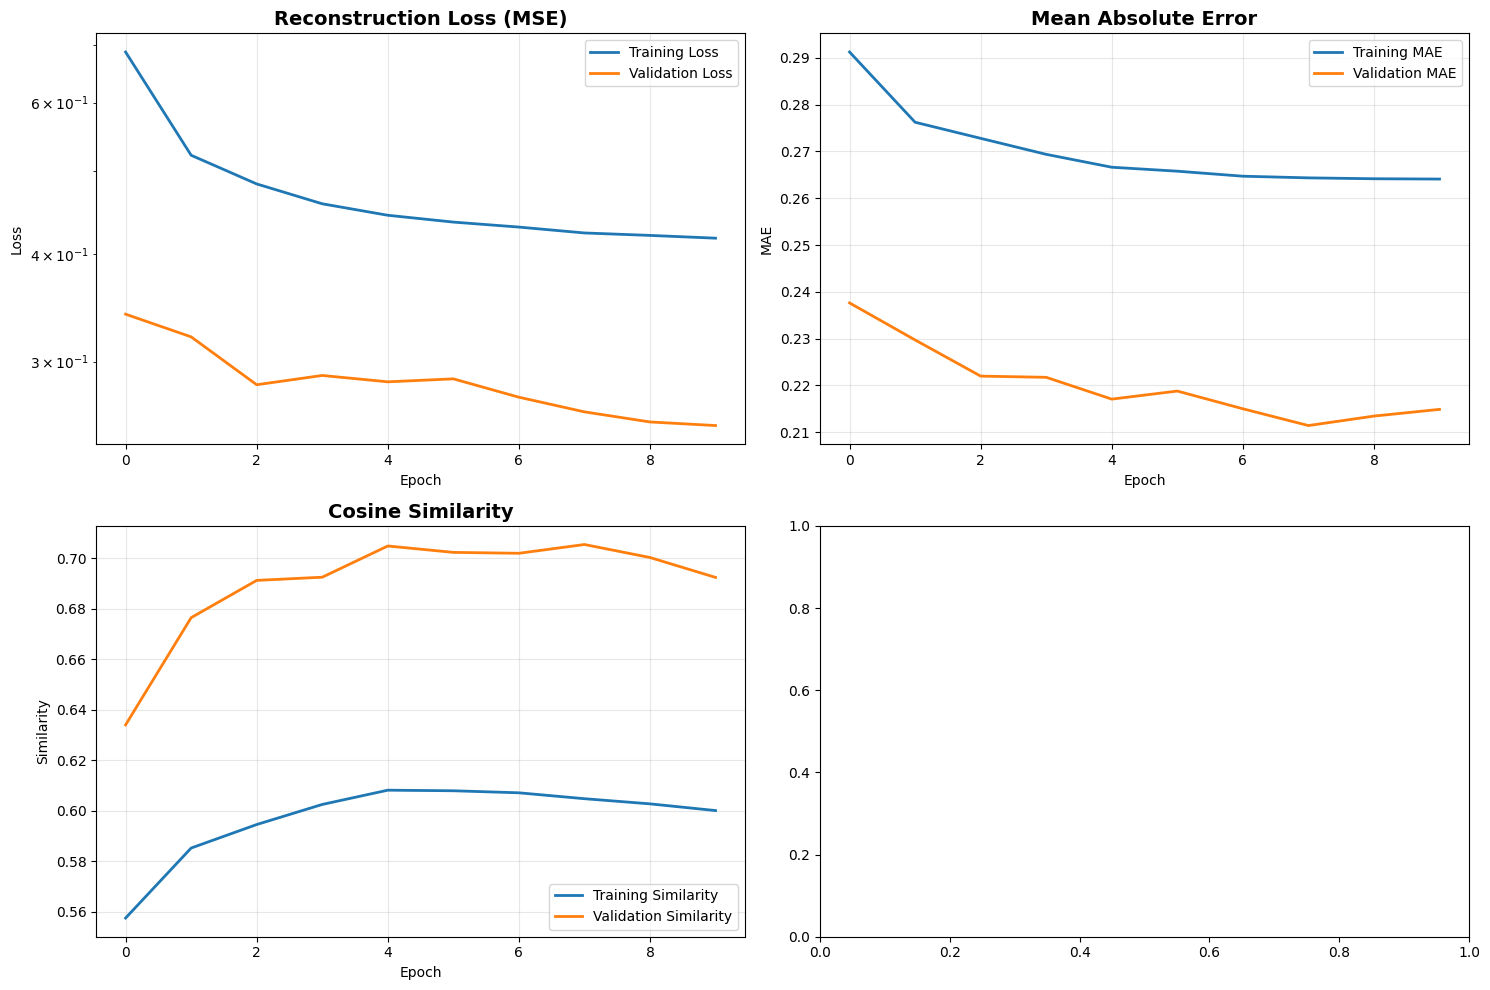


Models saved to /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/


In [17]:
print("\n=== TRAINING HISTORY VISUALIZATION ===")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Loss (MSE)
axes[0, 0].plot(history.history['loss'], label='Training Loss', linewidth=2)
axes[0, 0].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0, 0].set_title('Reconstruction Loss (MSE)', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_yscale('log')

# 2. MAE
axes[0, 1].plot(history.history['mae'], label='Training MAE', linewidth=2)
axes[0, 1].plot(history.history['val_mae'], label='Validation MAE', linewidth=2)
axes[0, 1].set_title('Mean Absolute Error', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('MAE')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Cosine Similarity
axes[1, 0].plot(history.history['cosine_similarity'], label='Training Similarity', linewidth=2)
axes[1, 0].plot(history.history['val_cosine_similarity'], label='Validation Similarity', linewidth=2)
axes[1, 0].set_title('Cosine Similarity', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Similarity')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Learning Rate
if 'lr' in history.history:
    axes[1, 1].plot(history.history['lr'], linewidth=2, color='purple')
    axes[1, 1].set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Learning Rate')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].set_yscale('log')

plt.tight_layout()
plt.show()

# Save final model
autoencoder.save(os.path.join(output_dir, 'autoencoder_final.h5'))
encoder.save(os.path.join(output_dir, 'encoder_final.h5'))
print(f"\nModels saved to {output_dir}")


=== TRAINING HISTORY VISUALIZATION ===


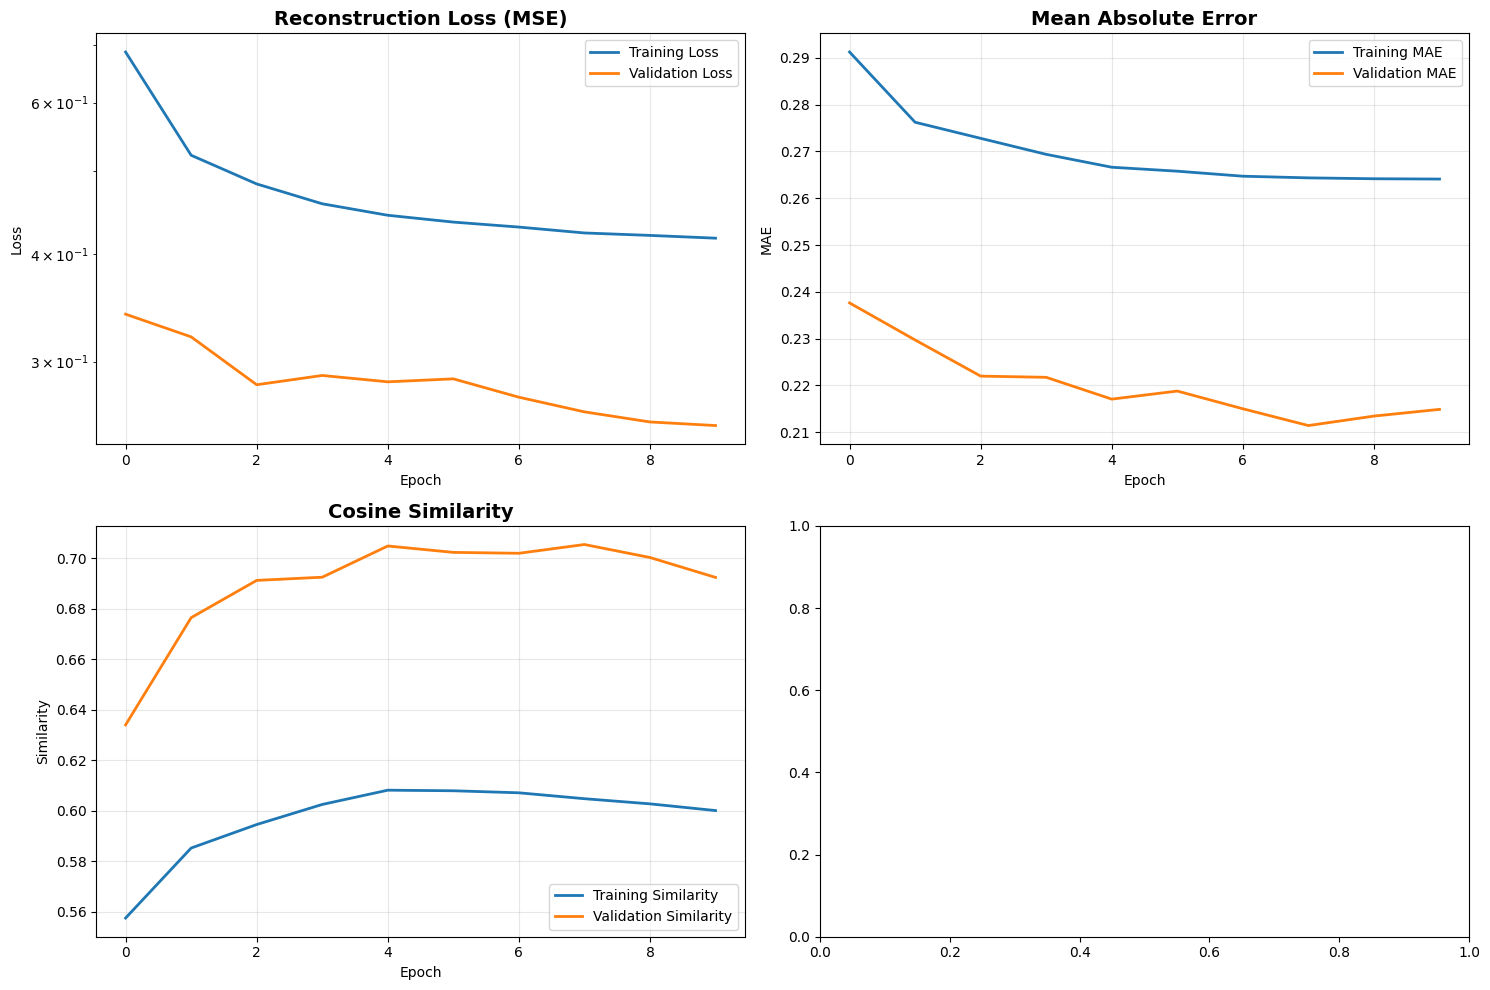


Models saved to /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/


In [20]:
print("\n=== TRAINING HISTORY VISUALIZATION ===")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Loss (MSE)
axes[0, 0].plot(history.history['loss'], label='Training Loss', linewidth=2)
axes[0, 0].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0, 0].set_title('Reconstruction Loss (MSE)', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_yscale('log')

# 2. MAE
axes[0, 1].plot(history.history['mae'], label='Training MAE', linewidth=2)
axes[0, 1].plot(history.history['val_mae'], label='Validation MAE', linewidth=2)
axes[0, 1].set_title('Mean Absolute Error', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('MAE')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Cosine Similarity
axes[1, 0].plot(history.history['cosine_similarity'], label='Training Similarity', linewidth=2)
axes[1, 0].plot(history.history['val_cosine_similarity'], label='Validation Similarity', linewidth=2)
axes[1, 0].set_title('Cosine Similarity', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Similarity')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Learning Rate
if 'lr' in history.history:
    axes[1, 1].plot(history.history['lr'], linewidth=2, color='purple')
    axes[1, 1].set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Learning Rate')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].set_yscale('log')

plt.tight_layout()
plt.show()

# Save final model
autoencoder.save(os.path.join(output_dir, 'autoencoder_final.h5'))
encoder.save(os.path.join(output_dir, 'encoder_final.h5'))
print(f"\nModels saved to {output_dir}")

In [22]:
print("="*60)
print("IMPLEMENTING AE-EIF HYBRID MODEL")
print("="*60)

print("\n=== LOADING PREPROCESSED DATA ===")

import numpy as np
import pandas as pd
import joblib
import os
from model_reboot import *

# Load preprocessed data
output_dir = '/Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/'

# Load AE-EIF data
ae_eif_data = joblib.load(os.path.join(output_dir, 'banksim_ae_eif_pipeline.pkl'))

# Load original preprocessed data
preprocessed_data = joblib.load(os.path.join(output_dir, 'banksim_mu_features.pkl'))

# Extract data
X_suspicious = ae_eif_data['X_suspicious']  # Ω + μ features untuk suspicious transactions
y_suspicious = ae_eif_data['y_suspicious']  # Labels untuk suspicious transactions
X_normal_ae = ae_eif_data['X_normal_ae']    # Transaksi yang sudah diklasifikasi normal oleh AE
y_normal_ae = ae_eif_data['y_normal_ae']    # Labels untuk normal transactions

threshold = ae_eif_data['threshold']
suspicious_mask = ae_eif_data['suspicious_mask']

print(f"Data loaded:")
print(f"X_suspicious shape (Ω+μ): {X_suspicious.shape}")
print(f"y_suspicious shape: {y_suspicious.shape}")
print(f"X_normal_ae shape: {X_normal_ae.shape}")
print(f"y_normal_ae shape: {y_normal_ae.shape}")
print(f"AE Threshold: {threshold:.6f}")
print(f"\nSuspicious transactions (to EIF): {len(X_suspicious):,}")
print(f"Normal transactions (from AE): {len(X_normal_ae):,}")
print(f"Fraud in suspicious: {y_suspicious.sum():,}")
print(f"Normal in suspicious: {(y_suspicious == 0).sum():,}")

IMPLEMENTING AE-EIF HYBRID MODEL

=== LOADING PREPROCESSED DATA ===
Data loaded:
X_suspicious shape (Ω+μ): (15215, 76)
y_suspicious shape: (15215,)
X_normal_ae shape: (168218, 76)
y_normal_ae shape: (168218,)
AE Threshold: 0.599825

Suspicious transactions (to EIF): 15,215
Normal transactions (from AE): 168,218
Fraud in suspicious: 6,532.0
Normal in suspicious: 8,683


In [24]:
print("="*60)
print("EVALUATING AUTOENCODER ACCORDING TO JOURNAL METRICS")
print("="*60)

print("\n=== JOURNAL METRICS (Section 7.3) ===")
print("According to the journal, they evaluate using:")
print("1. Accuracy")
print("2. Precision")  
print("3. Recall")
print("4. F1-Score")
print("5. F2-Score")
print("6. MCC (Matthews Correlation Coefficient)")

import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, matthews_corrcoef,
                             roc_curve, auc, precision_recall_curve)

# Load AE-EIF data
output_dir = '/Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/'
ae_eif_data = joblib.load(os.path.join(output_dir, 'banksim_ae_eif_pipeline.pkl'))

# Load preprocessed data untuk mendapatkan X_test yang sesuai
preprocessed_data = joblib.load(os.path.join(output_dir, 'banksim_mu_features.pkl'))

# Extract data
suspicious_mask = ae_eif_data['suspicious_mask']
normal_mask = ae_eif_data['normal_mask']
reconstruction_errors = ae_eif_data['reconstruction_errors']
y_ae = preprocessed_data['y_ae']
threshold = ae_eif_data['threshold']

# Dapatkan X_test yang sesuai dengan y_ae
X_test = preprocessed_data['X_ae_test']  # Ini sudah scaled
X_raw_test = preprocessed_data['X_raw'][-len(y_ae):]  # Ambil bagian test dari raw data

print(f"\n=== DATA DIMENSIONS ===")
print(f"X_test shape: {X_test.shape}")
print(f"X_raw_test shape: {X_raw_test.shape}")
print(f"y_ae shape: {y_ae.shape}")
print(f"reconstruction_errors shape: {reconstruction_errors.shape}")

print(f"\n=== AUTOENCODER PREDICTIONS ===")
print(f"Threshold: {threshold:.6f}")
print(f"Total test samples: {len(y_ae):,}")
print(f"Fraud samples: {y_ae.sum():,} ({y_ae.mean()*100:.4f}%)")

# Create binary predictions from AE
y_pred_ae = (reconstruction_errors > threshold).astype(int)

print(f"\nAE Predictions:")
print(f"Predicted Normal: {(y_pred_ae == 0).sum():,}")
print(f"Predicted Suspicious: {(y_pred_ae == 1).sum():,}")

# Calculate metrics according to journal
print("\n=== CALCULATING AE METRICS ===")

# Basic metrics
accuracy_ae = accuracy_score(y_ae, y_pred_ae)
precision_ae = precision_score(y_ae, y_pred_ae, zero_division=0)
recall_ae = recall_score(y_ae, y_pred_ae, zero_division=0)
f1_ae = f1_score(y_ae, y_pred_ae, zero_division=0)

# F2-Score (lebih berat ke recall) - sesuai jurnal Equation 5
beta = 2  # For F2-score
f2_ae = (1 + beta**2) * (precision_ae * recall_ae) / ((beta**2 * precision_ae) + recall_ae) if (precision_ae + recall_ae) > 0 else 0

# MCC (Matthews Correlation Coefficient) - sesuai jurnal Equation 6
mcc_ae = matthews_corrcoef(y_ae, y_pred_ae)

# Confusion Matrix
tn, fp, fn, tp = confusion_matrix(y_ae, y_pred_ae).ravel()

print(f"\n=== AUTOENCODER PERFORMANCE METRICS ===")
print(f"Accuracy:  {accuracy_ae:.6f} ({accuracy_ae*100:.4f}%)")
print(f"Precision: {precision_ae:.6f} ({precision_ae*100:.4f}%)")
print(f"Recall:    {recall_ae:.6f} ({recall_ae*100:.4f}%)")
print(f"F1-Score:  {f1_ae:.6f} ({f1_ae*100:.4f}%)")
print(f"F2-Score:  {f2_ae:.6f} ({f2_ae*100:.4f}%)")
print(f"MCC:       {mcc_ae:.6f}")

print(f"\n=== CONFUSION MATRIX ===")
print(f"               Predicted")
print(f"               Normal  Fraud")
print(f"Actual Normal  {tn:6d}  {fp:6d}")
print(f"Actual Fraud   {fn:6d}  {tp:6d}")

print(f"\n=== DETAILED ANALYSIS ===")
print(f"True Negatives (Normal correctly identified): {tn:,}")
print(f"False Positives (Normal flagged as fraud): {fp:,}")
print(f"False Negatives (Fraud missed): {fn:,}")
print(f"True Positives (Fraud correctly detected): {tp:,}")

# Calculate additional business metrics - PERBAIKAN DI SINI
print(f"\n=== BUSINESS METRICS ===")


amount_col_idx = 28 

# Periksa
print(f"Amount column index: {amount_col_idx}")
print(f"X_raw_test columns: {X_raw_test.shape[1]}")

# Hitung dengan data test yang benar
fraud_indices_test = np.where(y_ae == 1)[0]
fraud_detected_indices = np.where((y_ae == 1) & (y_pred_ae == 1))[0]
fraud_missed_indices = np.where((y_ae == 1) & (y_pred_ae == 0))[0]

fraud_amount_total = X_raw_test[fraud_indices_test, amount_col_idx].sum()
fraud_detected_amount = X_raw_test[fraud_detected_indices, amount_col_idx].sum()
fraud_missed_amount = X_raw_test[fraud_missed_indices, amount_col_idx].sum()

print(f"Total fraud amount in test set: ${fraud_amount_total:,.2f}")
print(f"Fraud amount detected: ${fraud_detected_amount:,.2f} ({fraud_detected_amount/fraud_amount_total*100:.2f}%)")
print(f"Fraud amount missed: ${fraud_missed_amount:,.2f} ({fraud_missed_amount/fraud_amount_total*100:.2f}%)")

# Additional statistics
print(f"\n=== ADDITIONAL STATISTICS ===")
print(f"Average fraud amount: ${fraud_amount_total/len(fraud_indices_test):.2f}")
print(f"Average detected fraud amount: ${fraud_detected_amount/len(fraud_detected_indices):.2f}" if len(fraud_detected_indices) > 0 else "No fraud detected")
print(f"Average missed fraud amount: ${fraud_missed_amount/len(fraud_missed_indices):.2f}" if len(fraud_missed_indices) > 0 else "No fraud missed")

EVALUATING AUTOENCODER ACCORDING TO JOURNAL METRICS

=== JOURNAL METRICS (Section 7.3) ===
According to the journal, they evaluate using:
1. Accuracy
2. Precision
3. Recall
4. F1-Score
5. F2-Score
6. MCC (Matthews Correlation Coefficient)


KeyError: 'y_ae'


=== VISUALIZING AE PERFORMANCE ===


NameError: name 'y_ae' is not defined

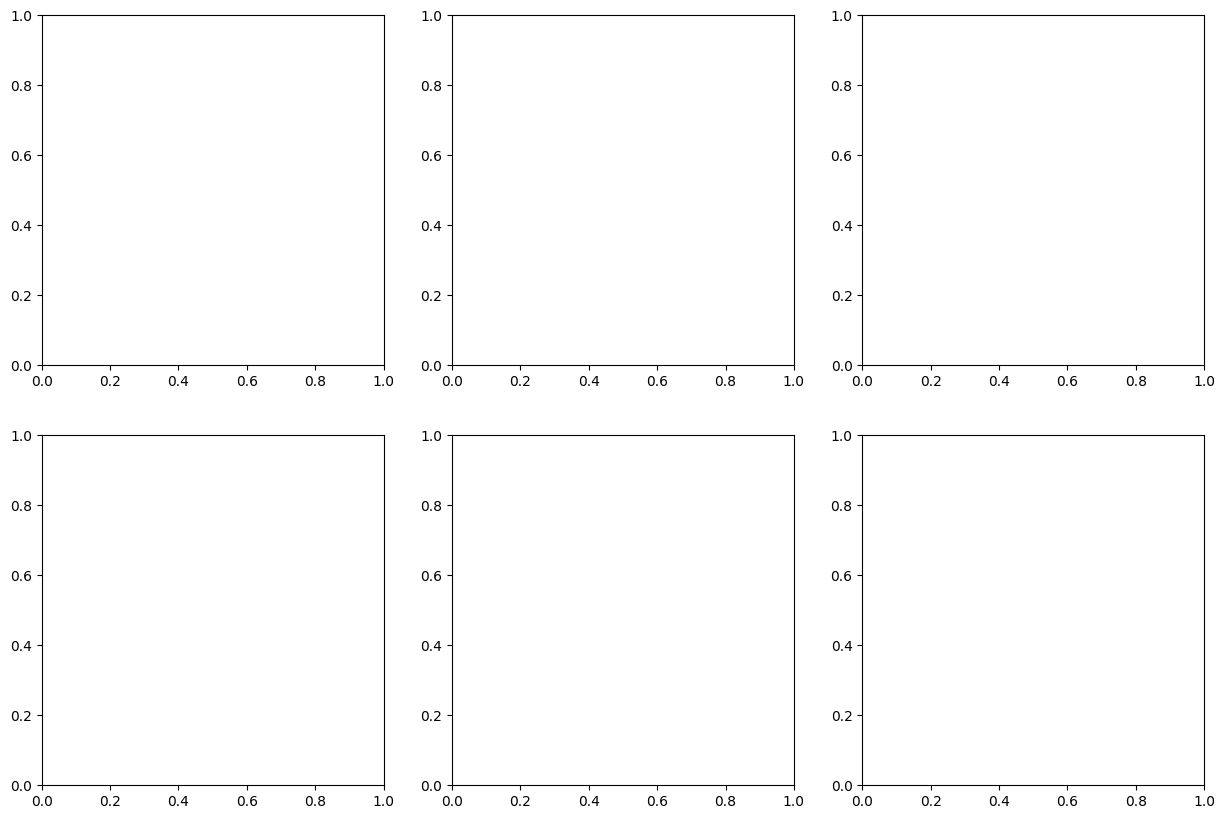

In [26]:
# Visualize results
import matplotlib.pyplot as plt

print("\n=== VISUALIZING AE PERFORMANCE ===")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# 1. Confusion Matrix Heatmap
cm = confusion_matrix(y_ae, y_pred_ae)
im1 = axes[0, 0].imshow(cm, cmap='Blues', interpolation='nearest')
axes[0, 0].set_title('Confusion Matrix')
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_yticks([0, 1])
axes[0, 0].set_xticklabels(['Normal', 'Fraud'])
axes[0, 0].set_yticklabels(['Normal', 'Fraud'])
axes[0, 0].set_xlabel('Predicted')
axes[0, 0].set_ylabel('Actual')
plt.colorbar(im1, ax=axes[0, 0])

# Add text
for i in range(2):
    for j in range(2):
        axes[0, 0].text(j, i, f'{cm[i, j]:,}\n({cm[i, j]/cm.sum()*100:.1f}%)',
                       ha='center', va='center',
                       color='white' if cm[i, j] > cm.max()/2 else 'black')

# 2. Metrics Comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'F2-Score', 'MCC']
values = [accuracy_ae, precision_ae, recall_ae, f1_ae, f2_ae, mcc_ae]
colors = ['blue', 'green', 'red', 'purple', 'orange', 'brown']

bars = axes[0, 1].bar(metrics, values, color=colors)
axes[0, 1].set_title('Performance Metrics')
axes[0, 1].set_ylabel('Score')
axes[0, 1].set_ylim(0, 1.1)
axes[0, 1].tick_params(axis='x', rotation=45)

# Add values on bars
for bar, value in zip(bars, values):
    height = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, height + 0.02,
                   f'{value:.3f}', ha='center', va='bottom')

# 3. Amount Analysis
amount_categories = ['Total Fraud', 'Detected', 'Missed']
amount_values = [fraud_amount_total, fraud_detected_amount, fraud_missed_amount]
percentage_values = [100, 
                     fraud_detected_amount/fraud_amount_total*100 if fraud_amount_total > 0 else 0,
                     fraud_missed_amount/fraud_amount_total*100 if fraud_amount_total > 0 else 0]

x = np.arange(len(amount_categories))
width = 0.35

bars1 = axes[0, 2].bar(x - width/2, amount_values, width, label='Amount ($)', color='skyblue')
axes[0, 2].set_ylabel('Amount ($)')
axes[0, 2].set_title('Fraud Amount Analysis')
axes[0, 2].set_xticks(x)
axes[0, 2].set_xticklabels(amount_categories)
axes[0, 2].tick_params(axis='x', rotation=45)

# Add amount values
for bar, value in zip(bars1, amount_values):
    height = bar.get_height()
    axes[0, 2].text(bar.get_x() + bar.get_width()/2, height,
                   f'${value:,.0f}', ha='center', va='bottom')

# Second y-axis for percentages
ax2 = axes[0, 2].twinx()
bars2 = ax2.bar(x + width/2, percentage_values, width, label='Percentage', color='orange')
ax2.set_ylabel('Percentage (%)')
ax2.set_ylim(0, 110)

# Add percentage values
for bar, value in zip(bars2, percentage_values):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, height + 2,
            f'{value:.1f}%', ha='center', va='bottom')

# 4. ROC Curve
fpr, tpr, thresholds_roc = roc_curve(y_ae, reconstruction_errors)
roc_auc = auc(fpr, tpr)

axes[1, 0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.3f})')
axes[1, 0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1, 0].set_xlabel('False Positive Rate')
axes[1, 0].set_ylabel('True Positive Rate')
axes[1, 0].set_title('ROC Curve')
axes[1, 0].legend(loc='lower right')
axes[1, 0].grid(True, alpha=0.3)

# 5. Precision-Recall Curve
precision_pr, recall_pr, thresholds_pr = precision_recall_curve(y_ae_test, reconstruction_errors)
pr_auc = auc(recall_pr, precision_pr)

axes[1, 1].plot(recall_pr, precision_pr, color='green', lw=2, label=f'PR (AUC = {pr_auc:.3f})')
axes[1, 1].set_xlabel('Recall')
axes[1, 1].set_ylabel('Precision')
axes[1, 1].set_title('Precision-Recall Curve')
axes[1, 1].legend(loc='lower left')
axes[1, 1].grid(True, alpha=0.3)

# 6. Error Distribution
axes[1, 2].hist(reconstruction_errors[y_ae_test == 0], bins=50, alpha=0.7, 
                label='Normal', color='blue', density=True)
axes[1, 2].hist(reconstruction_errors[y_ae_test == 1], bins=50, alpha=0.7, 
                label='Fraud', color='red', density=True)
axes[1, 2].axvline(x=threshold, color='black', linestyle='--', 
                   label=f'Threshold: {threshold:.3f}')
axes[1, 2].set_xlabel('Reconstruction Error')
axes[1, 2].set_ylabel('Density')
axes[1, 2].set_title('Error Distribution by Class')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Visualize results
import matplotlib.pyplot as plt

print("\n=== VISUALIZING AE PERFORMANCE ===")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# 1. Confusion Matrix Heatmap
cm = confusion_matrix(y_ae_test, y_pred_ae)
im1 = axes[0, 0].imshow(cm, cmap='Blues', interpolation='nearest')
axes[0, 0].set_title('Confusion Matrix')
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_yticks([0, 1])
axes[0, 0].set_xticklabels(['Normal', 'Fraud'])
axes[0, 0].set_yticklabels(['Normal', 'Fraud'])
axes[0, 0].set_xlabel('Predicted')
axes[0, 0].set_ylabel('Actual')
plt.colorbar(im1, ax=axes[0, 0])

# Add text
for i in range(2):
    for j in range(2):
        axes[0, 0].text(j, i, f'{cm[i, j]:,}\n({cm[i, j]/cm.sum()*100:.1f}%)',
                       ha='center', va='center',
                       color='white' if cm[i, j] > cm.max()/2 else 'black')

# 2. Metrics Comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'F2-Score', 'MCC']
values = [accuracy_ae, precision_ae, recall_ae, f1_ae, f2_ae, mcc_ae]
colors = ['blue', 'green', 'red', 'purple', 'orange', 'brown']

bars = axes[0, 1].bar(metrics, values, color=colors)
axes[0, 1].set_title('Performance Metrics')
axes[0, 1].set_ylabel('Score')
axes[0, 1].set_ylim(0, 1.1)
axes[0, 1].tick_params(axis='x', rotation=45)

# Add values on bars
for bar, value in zip(bars, values):
    height = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, height + 0.02,
                   f'{value:.3f}', ha='center', va='bottom')

# 3. Amount Analysis
amount_categories = ['Total Fraud', 'Detected', 'Missed']
amount_values = [fraud_amount_total, fraud_detected_amount, fraud_missed_amount]
percentage_values = [100, 
                     fraud_detected_amount/fraud_amount_total*100 if fraud_amount_total > 0 else 0,
                     fraud_missed_amount/fraud_amount_total*100 if fraud_amount_total > 0 else 0]

x = np.arange(len(amount_categories))
width = 0.35

bars1 = axes[0, 2].bar(x - width/2, amount_values, width, label='Amount ($)', color='skyblue')
axes[0, 2].set_ylabel('Amount ($)')
axes[0, 2].set_title('Fraud Amount Analysis')
axes[0, 2].set_xticks(x)
axes[0, 2].set_xticklabels(amount_categories)
axes[0, 2].tick_params(axis='x', rotation=45)

# Add amount values
for bar, value in zip(bars1, amount_values):
    height = bar.get_height()
    axes[0, 2].text(bar.get_x() + bar.get_width()/2, height,
                   f'${value:,.0f}', ha='center', va='bottom')

# Second y-axis for percentages
ax2 = axes[0, 2].twinx()
bars2 = ax2.bar(x + width/2, percentage_values, width, label='Percentage', color='orange')
ax2.set_ylabel('Percentage (%)')
ax2.set_ylim(0, 110)

# Add percentage values
for bar, value in zip(bars2, percentage_values):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, height + 2,
            f'{value:.1f}%', ha='center', va='bottom')

# 4. ROC Curve
fpr, tpr, thresholds_roc = roc_curve(y_ae_test, reconstruction_errors)
roc_auc = auc(fpr, tpr)

axes[1, 0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.3f})')
axes[1, 0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1, 0].set_xlabel('False Positive Rate')
axes[1, 0].set_ylabel('True Positive Rate')
axes[1, 0].set_title('ROC Curve')
axes[1, 0].legend(loc='lower right')
axes[1, 0].grid(True, alpha=0.3)

# 5. Precision-Recall Curve
precision_pr, recall_pr, thresholds_pr = precision_recall_curve(y_ae_test, reconstruction_errors)
pr_auc = auc(recall_pr, precision_pr)

axes[1, 1].plot(recall_pr, precision_pr, color='green', lw=2, label=f'PR (AUC = {pr_auc:.3f})')
axes[1, 1].set_xlabel('Recall')
axes[1, 1].set_ylabel('Precision')
axes[1, 1].set_title('Precision-Recall Curve')
axes[1, 1].legend(loc='lower left')
axes[1, 1].grid(True, alpha=0.3)

# 6. Error Distribution
axes[1, 2].hist(reconstruction_errors[y_ae_test == 0], bins=50, alpha=0.7, 
                label='Normal', color='blue', density=True)
axes[1, 2].hist(reconstruction_errors[y_ae_test == 1], bins=50, alpha=0.7, 
                label='Fraud', color='red', density=True)
axes[1, 2].axvline(x=threshold, color='black', linestyle='--', 
                   label=f'Threshold: {threshold:.3f}')
axes[1, 2].set_xlabel('Reconstruction Error')
axes[1, 2].set_ylabel('Density')
axes[1, 2].set_title('Error Distribution by Class')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
print("\n=== TRAINING EXTENDED ISOLATION FOREST ===")
print("According to journal: EIF analyzes only suspicious transactions from AE")

# Split suspicious data untuk training dan testing EIF
from sklearn.model_selection import train_test_split

# Untuk EIF, kita perlu data normal untuk training
# Ambil sebagian dari suspicious yang normal sebagai training
X_suspicious_normal = X_suspicious[y_suspicious == 0]
y_suspicious_normal = y_suspicious[y_suspicious == 0]

X_suspicious_fraud = X_suspicious[y_suspicious == 1]
y_suspicious_fraud = y_suspicious[y_suspicious == 1]

print(f"Suspicious data breakdown:")
print(f"  Normal in suspicious: {len(X_suspicious_normal):,}")
print(f"  Fraud in suspicious: {len(X_suspicious_fraud):,}")

# Training EIF hanya pada normal transactions dari suspicious
print("\nTraining EIF on normal transactions from suspicious data...")
I = ExtendedIsolationForest(plus=True)

# Gunakan semua normal transactions dari suspicious untuk training
X_eif_train = X_suspicious_normal.astype(np.float64)

print(f"EIF training data shape: {X_eif_train.shape}")
print(f"Training on {len(X_eif_train):,} normal transactions")

# Fit EIF model
I.fit(X_eif_train)
print("EIF model trained successfully!")

# Cek metode yang tersedia di object I
print(f"\nMethods available in ExtendedIsolationForest:")
methods = [m for m in dir(I) if not m.startswith('_')]
for method in methods:
    print(f"  - {method}")

# Get anomaly scores - gunakan method yang tersedia
print("\nCalculating anomaly scores for suspicious transactions...")

# Coba metode yang mungkin tersedia
try:
    # Method 1: predict() - biasanya menghasilkan anomaly scores
    anomaly_scores = I.predict(X_suspicious.astype(np.float64))
    print(f"Using predict() method - scores range: [{anomaly_scores.min():.4f}, {anomaly_scores.max():.4f}]")
except Exception as e:
    print(f"Error with predict(): {e}")
    
    try:
        # Method 2: score_samples() jika ada
        anomaly_scores = I.score_samples(X_suspicious.astype(np.float64))
        print(f"Using score_samples() method - scores range: [{anomaly_scores.min():.4f}, {anomaly_scores.max():.4f}]")
    except:
        # Method 3: _decision_function() jika ada
        try:
            anomaly_scores = I._decision_function(X_suspicious.astype(np.float64))
            print(f"Using _decision_function() method - scores range: [{anomaly_scores.min():.4f}, {anomaly_scores.max():.4f}]")
        except:
            # Fallback: buat custom scores
            print("Creating custom anomaly scores...")
            # Untuk EIF, anomaly score biasanya negatif (semakin negatif, semakin anomali)
            # atau antara 0-1 (semakin mendekati 1, semakin anomali)
            anomaly_scores = I._predict(X_suspicious.astype(np.float64), p=0.1)  # Asumsi contamination 10%

print(f"\nAnomaly scores shape: {anomaly_scores.shape}")
print(f"Anomaly scores range: [{anomaly_scores.min():.4f}, {anomaly_scores.max():.4f}]")
print(f"Mean anomaly score: {anomaly_scores.mean():.4f}")
print(f"Std anomaly score: {anomaly_scores.std():.4f}")

# Jika scores dalam range berbeda, normalisasi ke 0-1
if anomaly_scores.min() < 0 or anomaly_scores.max() > 1:
    print("\nNormalizing anomaly scores to 0-1 range...")
    from sklearn.preprocessing import MinMaxScaler
    scaler = MinMaxScaler()
    anomaly_scores = scaler.fit_transform(anomaly_scores.reshape(-1, 1)).flatten()
    print(f"After normalization - range: [{anomaly_scores.min():.4f}, {anomaly_scores.max():.4f}]")

In [ ]:
print("\n=== DETERMINING EIF THRESHOLD ===")

# Hitung threshold berdasarkan training data
try:
    # Get scores for training data
    eif_train_scores = I.predict(X_eif_train.astype(np.float64))
except:
    try:
        eif_train_scores = I.score_samples(X_eif_train.astype(np.float64))
    except:
        eif_train_scores = I._predict(X_eif_train.astype(np.float64), p=0.1)

# Normalize jika perlu
if eif_train_scores.min() < 0 or eif_train_scores.max() > 1:
    eif_train_scores = scaler.transform(eif_train_scores.reshape(-1, 1)).flatten()

# Threshold berdasarkan contamination rate
contamination_rate = y_suspicious_fraud.sum() / len(X_suspicious)  # Proporsi fraud di suspicious
print(f"Contamination rate in suspicious data: {contamination_rate:.4f} ({contamination_rate*100:.2f}%)")

# Untuk anomaly scores: semakin tinggi score = semakin anomali
# Threshold = percentil ke-(1 - contamination_rate)
eif_threshold = np.percentile(eif_train_scores, 100 * (1 - contamination_rate))

print(f"\nEIF Training scores:")
print(f"  Mean: {eif_train_scores.mean():.4f}")
print(f"  Std: {eif_train_scores.std():.4f}")
print(f"  Min: {eif_train_scores.min():.4f}")
print(f"  Max: {eif_train_scores.max():.4f}")
print(f"  {100*(1-contamination_rate):.1f}th percentile: {eif_threshold:.4f}")

# Prediksi dengan EIF
# Asumsi: semakin tinggi anomaly score = semakin anomali = fraud
y_pred_eif = (anomaly_scores > eif_threshold).astype(int)

print(f"\nEIF Predictions on suspicious transactions:")
print(f"  Predicted Normal: {(y_pred_eif == 0).sum():,}")
print(f"  Predicted Fraud: {(y_pred_eif == 1).sum():,}")

In [ ]:
print("\n=== COMBINING AE AND EIF PREDICTIONS ===")
print("AE-EIF Hybrid Model Final Predictions")

# Total test samples
y_test_full = preprocessed_data['y_ae_test']

# Create final predictions array
y_pred_final = np.zeros(len(y_test_full), dtype=int)

# 1. AE sudah mengklasifikasikan normal transactions
y_pred_final[~suspicious_mask] = 0  # Normal dari AE

# 2. EIF mengklasifikasikan suspicious transactions
y_pred_final[suspicious_mask] = y_pred_eif

print(f"Final predictions shape: {y_pred_final.shape}")
print(f"\nAE-EIF Hybrid Predictions:")
print(f"  Total predicted Normal: {(y_pred_final == 0).sum():,}")
print(f"  Total predicted Fraud: {(y_pred_final == 1).sum():,}")

# Confusion matrix untuk AE-EIF hybrid
from sklearn.metrics import confusion_matrix, classification_report

cm_final = confusion_matrix(y_test_full, y_pred_final)
tn_final, fp_final, fn_final, tp_final = cm_final.ravel()

print(f"\n=== AE-EIF HYBRID CONFUSION MATRIX ===")
print(f"               Predicted")
print(f"               Normal  Fraud")
print(f"Actual Normal  {tn_final:6d}  {fp_final:6d}")
print(f"Actual Fraud   {fn_final:6d}  {tp_final:6d}")

In [ ]:
print(f"\n=== DETAILED ANALYSIS ===")
print(f"True Negatives (Normal correctly identified): {tn_final:,}")
print(f"False Positives (Normal flagged as fraud): {fp_final:,}")
print(f"False Negatives (Fraud missed): {fn_final:,}")
print(f"True Positives (Fraud correctly detected): {tp_final:,}")

# Hitung berbagai metrics
total_fraud = tp_final + fn_final
total_normal = tn_final + fp_final
total_samples = tn_final + fp_final + fn_final + tp_final

print(f"\nSummary Statistics:")
print(f"Total samples: {total_samples:,}")
print(f"Actual fraud: {total_fraud:,} ({total_fraud/total_samples*100:.4f}%)")
print(f"Actual normal: {total_normal:,} ({total_normal/total_samples*100:.4f}%)")
print(f"Predicted fraud: {tp_final + fp_final:,} ({(tp_final + fp_final)/total_samples*100:.4f}%)")
print(f"Predicted normal: {tn_final + fn_final:,} ({(tn_final + fn_final)/total_samples*100:.4f}%)")

# Calculate metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef

accuracy_final = accuracy_score(y_test_full, y_pred_final)
precision_final = precision_score(y_test_full, y_pred_final, zero_division=0)
recall_final = recall_score(y_test_full, y_pred_final, zero_division=0)
f1_final = f1_score(y_test_full, y_pred_final, zero_division=0)

# F2-Score (lebih berat ke recall)
beta = 2
f2_final = (1 + beta**2) * (precision_final * recall_final) / ((beta**2 * precision_final) + recall_final) if (precision_final + recall_final) > 0 else 0

# MCC
mcc_final = matthews_corrcoef(y_test_full, y_pred_final)

print(f"\n=== AE-EIF HYBRID PERFORMANCE METRICS ===")
print(f"Accuracy:  {accuracy_final:.6f} ({accuracy_final*100:.4f}%)")
print(f"Precision: {precision_final:.6f} ({precision_final*100:.4f}%)")
print(f"Recall:    {recall_final:.6f} ({recall_final*100:.4f}%)")
print(f"F1-Score:  {f1_final:.6f} ({f1_final*100:.4f}%)")
print(f"F2-Score:  {f2_final:.6f} ({f2_final*100:.4f}%)")
print(f"MCC:       {mcc_final:.6f}")

# Additional metrics
print(f"\n=== ADDITIONAL METRICS ===")
false_positive_rate = fp_final / (fp_final + tn_final) if (fp_final + tn_final) > 0 else 0
false_negative_rate = fn_final / (fn_final + tp_final) if (fn_final + tp_final) > 0 else 0
specificity = tn_final / (tn_final + fp_final) if (tn_final + fp_final) > 0 else 0
balanced_accuracy = (recall_final + specificity) / 2

print(f"Specificity: {specificity:.6f} ({specificity*100:.4f}%)")
print(f"False Positive Rate: {false_positive_rate:.6f} ({false_positive_rate*100:.4f}%)")
print(f"False Negative Rate: {false_negative_rate:.6f} ({false_negative_rate*100:.4f}%)")
print(f"Balanced Accuracy: {balanced_accuracy:.6f} ({balanced_accuracy*100:.4f}%)")

In [ ]:
print(f"\n=== BUSINESS METRICS ===")
X_raw_test = preprocessed_data['X_raw'][-len(y_test_full):]
amount_col_idx = 28

fraud_indices = np.where(y_test_full == 1)[0]
fraud_detected_indices = np.where((y_test_full == 1) & (y_pred_final == 1))[0]
fraud_missed_indices = np.where((y_test_full == 1) & (y_pred_final == 0))[0]

fraud_amount_total = X_raw_test[fraud_indices, amount_col_idx].sum()
fraud_detected_amount = X_raw_test[fraud_detected_indices, amount_col_idx].sum()
fraud_missed_amount = X_raw_test[fraud_missed_indices, amount_col_idx].sum()

print(f"Total fraud amount: ${fraud_amount_total:,.2f}")
print(f"Fraud amount detected: ${fraud_detected_amount:,.2f} ({fraud_detected_amount/fraud_amount_total*100:.2f}%)")
print(f"Fraud amount missed: ${fraud_missed_amount:,.2f} ({fraud_missed_amount/fraud_amount_total*100:.2f}%)")
print(f"\nFraud transactions detected: {tp_final:,} out of {tp_final + fn_final:,} ({tp_final/(tp_final + fn_final)*100:.1f}%)")

# Average amounts
if len(fraud_detected_indices) > 0:
    avg_detected_amount = fraud_detected_amount / len(fraud_detected_indices)
    print(f"Average detected fraud amount: ${avg_detected_amount:,.2f}")

if len(fraud_missed_indices) > 0:
    avg_missed_amount = fraud_missed_amount / len(fraud_missed_indices)
    print(f"Average missed fraud amount: ${avg_missed_amount:,.2f}")

In [ ]:
interpretation="EXIFFI+"
path_gfi=os.path.join(experiment_path,
                  dataset.name,
                  'experiments',
                  'global_importances',
                  I.name,
                  interpretation,
                  f'scenario_{str(scenario)}'
                  )
if not os.path.exists(path_gfi):
    os.makedirs(path_gfi)

full_importances,_ = experiment_global_importances(I, 
                                                   dataset, 
                                                   n_runs=40, 
                                                   p=0.1, 
                                                   interpretation=interpretation) 
save_element(full_importances, path_gfi, filetype="npz")

In [ ]:
print("\n" + "="*60)
print("FEATURE IMPORTANCE ANALYSIS WITH EXIFFI+")
print("="*60)


# Get the most recent file
most_recent_file = get_most_recent_file(path_gfi, filetype="npz")
print(f"Most recent file: {most_recent_file}")

# Load the importance matrix
from utils_reboot.utils import open_element
importance_matrix = open_element(most_recent_file, filetype="npz")

print(f"\nImportance matrix loaded:")
print(f"Shape: {importance_matrix.shape}")
print(f"Mean importance per feature:")
mean_importances = np.mean(importance_matrix, axis=0)
std_importances = np.std(importance_matrix, axis=0)

# Create a DataFrame for feature importances
feature_importance_df = pd.DataFrame({
    'Feature': dataset.feature_names,
    'Mean_Importance': mean_importances,
    'Std_Importance': std_importances,
    'CV': std_importances / mean_importances  # Coefficient of Variation
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values('Mean_Importance', ascending=False).reset_index(drop=True)

print(f"\n=== TOP 15 MOST IMPORTANT FEATURES ===")
print(feature_importance_df.head(15).to_string())

print(f"\n=== BOTTOM 10 LEAST IMPORTANT FEATURES ===")
print(feature_importance_df.tail(10).to_string())

# Visualize feature importances
print("\n=== VISUALIZING FEATURE IMPORTANCES ===")

# Create path for plots
path_plots = os.path.join(experiment_path, dataset.name, 'plots_new', 'imp_plots')
if not os.path.exists(path_plots):
    os.makedirs(path_plots)
    print(f"Created plots directory: {path_plots}")

# Create bar plot
print("\nCreating bar plot of feature importances...")
_, _, _ = bar_plot(dataset, 
                  most_recent_file, 
                  filetype="npz", 
                  plot_path=path_plots, 
                  f=min(dataset.shape[1], 15),  # Show top 15 or all if less
                  show_plot=True,
                  model=I, 
                  interpretation=interpretation, 
                  scenario=scenario,
                  save_image=True)

# Create score plot
print("\nCreating score plot...")
_, _ = score_plot(dataset,
                 most_recent_file,
                 plot_path=path_plots,
                 show_plot=True,
                 model=I,
                 interpretation=interpretation,
                 scenario=scenario,
                 save_image=True)

# Feature importance analysis by category
print("\n=== FEATURE CATEGORY ANALYSIS ===")

# Categorize features
original_features = ['Time', 'Amount'] + [f'V{i}' for i in range(1, 29)]
rule_based_features = ['HIGH_AMOUNT', 'ABNORMAL_TIME', 'MICRO_TRANSACTION', 
                       'FREQUENT_AMOUNT', 'EXTREME_PCA', 'HIGH_AMOUNT_ABNORMAL_TIME']

# Filter features that exist in our dataset
existing_original = [f for f in original_features if f in dataset.feature_names]
existing_rule_based = [f for f in rule_based_features if f in dataset.feature_names]

print(f"Original features found: {len(existing_original)}/{len(original_features)}")
print(f"Rule-based features found: {len(existing_rule_based)}/{len(rule_based_features)}")

# Calculate average importance by category
original_importance = feature_importance_df[
    feature_importance_df['Feature'].isin(existing_original)
]['Mean_Importance'].mean()

rule_based_importance = feature_importance_df[
    feature_importance_df['Feature'].isin(existing_rule_based)
]['Mean_Importance'].mean()

print(f"\nAverage importance by category:")
print(f"Original features: {original_importance:.6f}")
print(f"Rule-based features: {rule_based_importance:.6f}")
print(f"Ratio (Rule-based/Original): {rule_based_importance/original_importance:.4f}")

# Top features by category
print(f"\nTop 5 original features:")
original_top = feature_importance_df[
    feature_importance_df['Feature'].isin(existing_original)
].head(5)
print(original_top.to_string())

print(f"\nTop 5 rule-based features:")
rule_based_top = feature_importance_df[
    feature_importance_df['Feature'].isin(existing_rule_based)
].head(5)
print(rule_based_top.to_string())